In [ ]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter
from datasets import Dataset, DatasetDict
import evaluate

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Count the number of samples in each category in the train set

In [ ]:
import pathlib
from collections import Counter

DATA_DIR = pathlib.Path("/content/")
TRAIN_FILE = DATA_DIR / "train.txt"
DEV_FILE = DATA_DIR / "dev.txt"
TEST_FILE = DATA_DIR / "test.txt"

TAG_ORDER = [
    "B-LOC", "B-ORG", "B-PER", "B-TIME", "B-TTL",
    "I-LOC", "I-ORG", "I-PER", "I-TIME", "I-TTL",
    "O"
]

def count_ordered_tags(file_path):
    counter = Counter()

    with open(file_path, encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 2:
                continue
            tag = parts[-1]
            if tag in TAG_ORDER:
                counter[tag] += 1

    return [counter.get(tag, 0) for tag in TAG_ORDER]


def print_tag_counts(name, file_path):
    counts = count_ordered_tags(file_path)
    print(f"\n{name} tag counts (0->10):")
    for i, tag in enumerate(TAG_ORDER):
        print(f"{i} -> {tag}: {counts[i]}")


print_tag_counts("TRAIN", TRAIN_FILE)



TRAIN tag counts (0->10):
0 -> B-LOC: 789
1 -> B-ORG: 1269
2 -> B-PER: 970
3 -> B-TIME: 602
4 -> B-TTL: 757
5 -> I-LOC: 587
6 -> I-ORG: 1534
7 -> I-PER: 752
8 -> I-TIME: 1568
9 -> I-TTL: 247
10 -> O: 78886


In [ ]:

MODEL_CHECKPOINT = "uhhlt/am-roberta"
OUTPUT_DIR = "./ner_amharic"

NUM_TRAIN_EPOCHS = 10
PER_DEVICE_TRAIN_BATCH_SIZE = 16
PER_DEVICE_EVAL_BATCH_SIZE = 16

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.05
LOG_DIR = "./logs"
PUSH_TO_HUB = False

os.environ["WANDB_DISABLED"] = "true"

In [ ]:
def read_conll(path):
    sentences, labels = [], []
    tokens, tags = [], []

    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens:
                    sentences.append(tokens)
                    labels.append(tags)
                    tokens, tags = [], []
            else:
                parts = line.split()
                tokens.append(" ".join(parts[:-1]))
                tags.append(parts[-1])

        if tokens:
            sentences.append(tokens)
            labels.append(tags)

    return sentences, labels



In [ ]:

train_tokens, train_tags = read_conll(TRAIN_FILE)
dev_tokens, dev_tags = read_conll(DEV_FILE)
test_tokens, test_tags = read_conll(TEST_FILE)

label_list = sorted(set(
    t for s in train_tags + dev_tags + test_tags for t in s
))
label_to_id = {l: i for i, l in enumerate(label_list)}

print("Label → ID mapping:")
for label, idx in label_to_id.items():
    print(f"{idx:2d} -> {label}")

def encode(tags):
    return [[label_to_id[t] for t in sent] for sent in tags]

dataset = DatasetDict({
    "train": Dataset.from_dict({"tokens": train_tokens, "ner_tags": encode(train_tags)}),
    "validation": Dataset.from_dict({"tokens": dev_tokens, "ner_tags": encode(dev_tags)}),
    "test": Dataset.from_dict({"tokens": test_tokens, "ner_tags": encode(test_tags)}),
})


Label → ID mapping:
 0 -> B-LOC
 1 -> B-ORG
 2 -> B-PER
 3 -> B-TIME
 4 -> B-TTL
 5 -> I-LOC
 6 -> I-ORG
 7 -> I-PER
 8 -> I-TIME
 9 -> I-TTL
10 -> O


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_CHECKPOINT,
    add_prefix_space=True
)


def tokenize_and_align(examples):
    tok = tokenizer(examples["tokens"], is_split_into_words=True, truncation=True)
    labels = []

    for i, labs in enumerate(examples["ner_tags"]):
        word_ids = tok.word_ids(batch_index=i)
        prev = None
        aligned = []

        for w in word_ids:
            if w is None:
                aligned.append(-100)
            elif w != prev:
                aligned.append(labs[w])
            else:
                aligned.append(-100)
            prev = w

        labels.append(aligned)

    tok["labels"] = labels
    return tok

tokenized = dataset.map(tokenize_and_align, batched=True)


Map:   0%|          | 0/3465 [00:00<?, ? examples/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Map:   0%|          | 0/437 [00:00<?, ? examples/s]

Map:   0%|          | 0/403 [00:00<?, ? examples/s]

In [ ]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(label_list),
    hidden_dropout_prob=0.3,
    attention_probs_dropout_prob=0.3
)

model.config.id2label = {i: l for i, l in enumerate(label_list)}
model.config.label2id = label_to_id


model.safetensors:   0%|          | 0.00/1.77G [00:00<?, ?B/s]

Some weights of RobertaForTokenClassification were not initialized from the model checkpoint at uhhlt/am-roberta and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
for name, param in model.roberta.named_parameters():
    if "layer.0" in name or "layer.1" in name or "layer.2" in name:
        param.requires_grad = False

In [ ]:
metric = evaluate.load("seqeval")

def compute_metrics(p):
    preds, labels = p
    preds = np.argmax(preds, axis=2)

    true_preds, true_labels = [], []
    for pr, lb in zip(preds, labels):
        tp, tl = [], []
        for p_i, l_i in zip(pr, lb):
            if l_i != -100:
                tp.append(label_list[p_i])
                tl.append(label_list[l_i])
        true_preds.append(tp)
        true_labels.append(tl)

    res = metric.compute(predictions=true_preds, references=true_labels)
    return {"accuracy": res["overall_accuracy"], "f1": res["overall_f1"]}


In [ ]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BATCH_SIZE,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    weight_decay=WEIGHT_DECAY,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_dir=LOG_DIR,
    push_to_hub=PUSH_TO_HUB,
)


Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    tokenizer=tokenizer,
    data_collator=DataCollatorForTokenClassification(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)


/tmp/ipython-input-3051318341.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [ ]:
trainer.train()
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.809900,0.344953,0.908335,0.060510
2,0.304000,0.219724,0.936630,0.332973
3,0.224200,0.176441,0.946122,0.500000
4,0.190500,0.162280,0.949828,0.555230
5,0.172100,0.156157,0.951275,0.569767
6,0.157800,0.150740,0.952631,0.584354
7,0.149600,0.148204,0.953263,0.592731
8,0.147000,0.147109,0.953173,0.600939
9,0.145500,0.146148,0.952992,0.593692
10,0.141300,0.145988,0.953354,0.595349


/usr/local/lib/python3.12/dist-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


('./ner_amharic/tokenizer_config.json',
 './ner_amharic/special_tokens_map.json',
 './ner_amharic/vocab.json',
 './ner_amharic/merges.txt',
 './ner_amharic/added_tokens.json',
 './ner_amharic/tokenizer.json')

In [ ]:
from seqeval.metrics import classification_report

# ---------------------------
# Evaluate on TRAIN set
# ---------------------------
train_metrics = trainer.evaluate(tokenized["train"])
print("\nTrain metrics:")
for k, v in train_metrics.items():
    print(f"{k}: {v:.4f}")



Train metrics:
eval_loss: 0.1059
eval_accuracy: 0.9637
eval_f1: 0.6642
eval_runtime: 7.3743
eval_samples_per_second: 469.8740
eval_steps_per_second: 29.4260
epoch: 10.0000


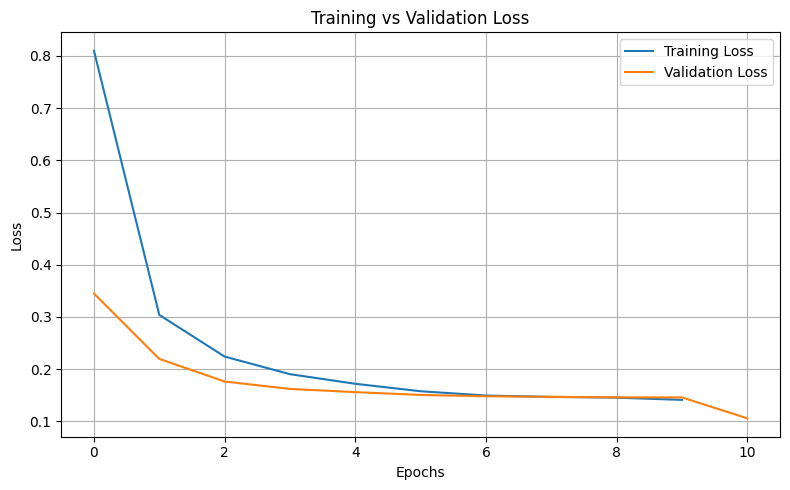

In [ ]:
history = pd.DataFrame(trainer.state.log_history)

plt.figure(figsize=(8, 5))
plt.plot(history["loss"].dropna().values, label="Training Loss")
plt.plot(history["eval_loss"].dropna().values, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
predictions, labels, _ = trainer.predict(tokenized["test"])
predictions = np.argmax(predictions, axis=2)

true_preds = []
true_labels = []

for pr, lb in zip(predictions, labels):
    sent_preds = []
    sent_labels = []

    for p_i, l_i in zip(pr, lb):
        if l_i != -100:
            sent_preds.append(label_list[p_i])
            sent_labels.append(label_list[l_i])

    true_preds.append(sent_preds)
    true_labels.append(sent_labels)

from seqeval.metrics import classification_report

print("\nClassification Report:")
print(classification_report(true_labels, true_preds))


from sklearn.metrics import confusion_matrix, accuracy_score


y_true, y_pred = [], []

for pr, lb in zip(predictions, labels):
    for p_i, l_i in zip(pr, lb):
        if l_i != -100:
            y_true.append(l_i)
            y_pred.append(p_i)


cm = confusion_matrix(y_true, y_pred)
acc = accuracy_score(y_true, y_pred)

print("Accuracy:", acc)




Classification Report:
              precision    recall  f1-score   support

         LOC       0.40      0.44      0.42        79
         ORG       0.54      0.54      0.54       170
         PER       0.93      0.86      0.90       140
        TIME       0.37      0.54      0.44        82
         TTL       0.83      0.88      0.85       105

   micro avg       0.62      0.67      0.64       576
   macro avg       0.62      0.65      0.63       576
weighted avg       0.65      0.67      0.65       576

Accuracy: 0.953983969825554


<Figure size 1200x1200 with 0 Axes>

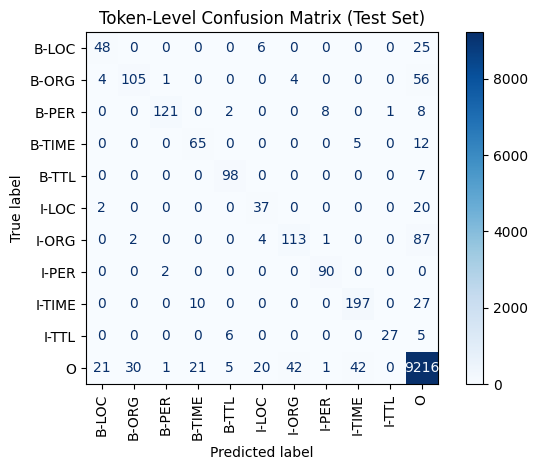

In [ ]:
plt.figure(figsize=(12, 12))
disp = ConfusionMatrixDisplay(cm, display_labels=label_list)
disp.plot(cmap="Blues", xticks_rotation=90)
plt.title("Token-Level Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

In [ ]:
!pip install --upgrade transformers datasets evaluate seqeval
